<a href="https://colab.research.google.com/github/hebakhattabGIS/CA_AIS2_G1_Ml/blob/main/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [5]:
data = pd.read_csv ('/kaggle/input/creditcardfraud/creditcard.csv')

In [6]:
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
data = data.drop(['Time'],axis=1)

<BarContainer object of 2 artists>

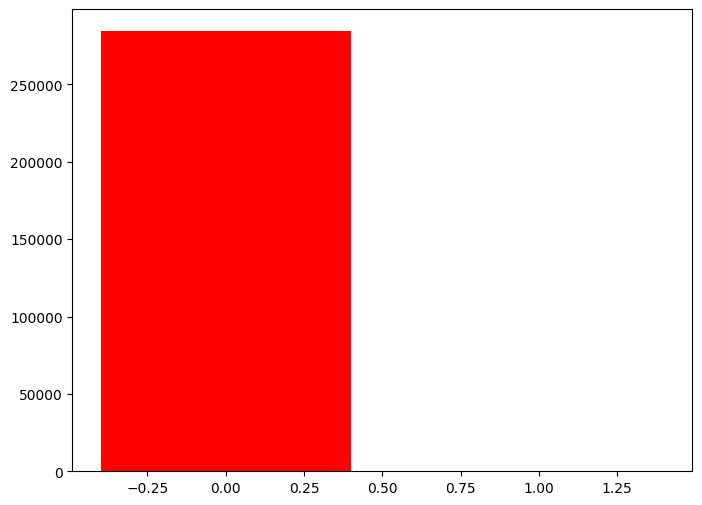

In [9]:
rcParams['figure.figsize'] = 8,6
plt.bar(data['Class'].unique(), data['Class'].value_counts(), color= ['red', 'green'] )

In [13]:
x=data.drop(['Class'], axis=1)
y = data['Class']

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=50)

In [19]:
hyper_param = {'criterion' : ['entropy'], 'max_depth': [4]}
tree_GS = GridSearchCV(DecisionTreeClassifier(), hyper_param, scoring='roc_auc', cv = 5, verbose=2)
tree_cross_grid = tree_GS.fit(x_train, y_train)
print("best_params", tree_cross_grid.best_params_)
print("best_params", tree_cross_grid.best_estimator_)
print("best_params", tree_cross_grid.best_score_)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[CV] END .....................criterion=entropy, max_depth=4; total time=   5.5s
[CV] END .....................criterion=entropy, max_depth=4; total time=   6.2s
[CV] END .....................criterion=entropy, max_depth=4; total time=   5.5s
[CV] END .....................criterion=entropy, max_depth=4; total time=   5.9s
[CV] END .....................criterion=entropy, max_depth=4; total time=   5.8s
best_params {'criterion': 'entropy', 'max_depth': 4}
best_params DecisionTreeClassifier(criterion='entropy', max_depth=4)
best_params 0.9511708068551453


In [21]:
Hyper_paramters={'n_estimators': [3,5,7,9]}
tree_GS = GridSearchCV(BaggingClassifier(), Hyper_paramters, scoring='roc_auc', cv = 5 , verbose=2)
tree_cross_grid = tree_GS.fit(x_train, y_train)

print("best_params_ ",tree_cross_grid.best_params_)
print("best_params_ ",tree_cross_grid.best_estimator_)
print("best_params_ ",tree_cross_grid.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END .....................................n_estimators=3; total time=  32.6s
[CV] END .....................................n_estimators=3; total time=  31.2s
[CV] END .....................................n_estimators=3; total time=  36.8s
[CV] END .....................................n_estimators=3; total time=  38.2s
[CV] END .....................................n_estimators=3; total time=  44.9s
[CV] END .....................................n_estimators=5; total time= 1.1min
[CV] END .....................................n_estimators=5; total time= 1.0min
[CV] END .....................................n_estimators=5; total time=  49.7s
[CV] END .....................................n_estimators=5; total time=  54.7s
[CV] END .....................................n_estimators=5; total time=  59.6s
[CV] END .....................................n_estimators=7; total time= 1.4min
[CV] END .....................................n_e

In [ ]:
Hyper_paramters={'criterion':['entropy'],'max_depth':[4,10], 'n_estimators':[50,100], 'max_features': ['sqrt']}
tree_GS = GridSearchCV(RandomForestClassifier(), Hyper_paramters, scoring='roc_auc', cv = 5 , verbose=2)
tree_cross_grid = tree_GS.fit(x_train, y_train)

print("best_params_ ",tree_cross_grid.best_params_)
print("best_params_ ",tree_cross_grid.best_estimator_)
print("best_params_ ",tree_cross_grid.best_score_)